In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)


In [6]:
from google.colab import files

uploaded = files.upload()

Saving gold_stock.csv to gold_stock (1).csv


In [7]:

import os

print(os.listdir("/content"))


['.config', 'gold_stock.csv', 'gold_stock (1).csv', 'sample_data']


In [8]:

import glob
import pandas as pd

files = glob.glob("/content/gold_stock*.csv")

print("Available gold CSV files:", files)

if files:
    df = pd.read_csv(files[0])
    print(df.head(10))
    print("Dataset dimensions:", df.shape)
    print("Column names:", df.columns.tolist())
else:
    print("No gold_stock CSV file found. Please upload it again.")


Available gold CSV files: ['/content/gold_stock.csv', '/content/gold_stock (1).csv']
        Price              Close                High                 Low  \
0      Ticker               GOLD                GOLD                GOLD   
1        Date                NaN                 NaN                 NaN   
2  2014-03-17  4.711997032165527    4.85016815549002   4.425025639793251   
3  2014-03-18  5.048568248748779   5.278853682840762   4.694282757608514   
4  2014-03-19  4.959996223449707  5.1017102661133835    4.90685354191906   
5  2014-03-20  4.959996223449707   4.959996223449707   4.889493292947593   
6  2014-03-21   4.69074010848999    4.92456849288367  4.6057116665055595   
7  2014-03-24  4.400225639343262   4.623425529787973  4.2691400537562965   
8  2014-03-25  4.761595249176025   4.761595249176025   4.322281469155266   
9  2014-03-26  4.417940616607666    4.74742592698738   4.339997706057698   

                Open  Volume  
0               GOLD    GOLD  
1               

In [9]:

df = df[df["Price"].astype(str).str.match(r"\d{4}-\d{2}-\d{2}")].copy()

df.rename(columns={"Price": "Date"}, inplace=True)

df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

columns = ["Close", "High", "Low", "Open", "Volume"]

for col in columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df.dropna(subset=["Date"] + columns, inplace=True)
df.drop_duplicates(subset=["Date"], keep="last", inplace=True)

df.sort_values("Date", inplace=True)
df.reset_index(drop=True, inplace=True)

print(df.head())
print("Cleaned dimensions:", df.shape)
print("\nMissing values:")
print(df.isnull().sum())


        Date     Close      High       Low      Open  Volume
0 2014-03-17  4.711997  4.850168  4.425026  4.425026   68200
1 2014-03-18  5.048568  5.278854  4.694283  4.711997  135600
2 2014-03-19  4.959996  5.101710  4.906854  5.013139   25600
3 2014-03-20  4.959996  4.959996  4.889493  4.959996    8200
4 2014-03-21  4.690740  4.924568  4.605712  4.924568   10600
Cleaned dimensions: (2968, 6)

Missing values:
Date      0
Close     0
High      0
Low       0
Open      0
Volume    0
dtype: int64


In [10]:

df["Daily_Return"] = df["Close"].pct_change(fill_method=None)

df["MA_5_Ratio"] = (
    df["Close"] / df["Close"].rolling(5, min_periods=1).mean()
)

df["MA_20_Ratio"] = (
    df["Close"] / df["Close"].rolling(20, min_periods=1).mean()
)

df["Volatility_5"] = (
    df["Daily_Return"].rolling(5, min_periods=1).std()
)

df["Volume_Change"] = df["Volume"].pct_change(fill_method=None)

df.replace([np.inf, -np.inf], np.nan, inplace=True)

df["Daily_Return"] = df["Daily_Return"].fillna(0)
df["Volume_Change"] = df["Volume_Change"].fillna(0)
df["Volatility_5"] = df["Volatility_5"].fillna(0)

print(df.head())
print("Dataset dimensions:", df.shape)
print(df.isnull().sum())


        Date     Close      High       Low      Open  Volume  Daily_Return  \
0 2014-03-17  4.711997  4.850168  4.425026  4.425026   68200      0.000000   
1 2014-03-18  5.048568  5.278854  4.694283  4.711997  135600      0.071429   
2 2014-03-19  4.959996  5.101710  4.906854  5.013139   25600     -0.017544   
3 2014-03-20  4.959996  4.959996  4.889493  4.959996    8200      0.000000   
4 2014-03-21  4.690740  4.924568  4.605712  4.924568   10600     -0.054286   

   MA_5_Ratio  MA_20_Ratio  Volatility_5  Volume_Change  
0    1.000000     1.000000      0.000000       0.000000  
1    1.034483     1.034483      0.000000       0.988270  
2    1.010830     1.010830      0.062913      -0.811209  
3    1.008101     1.008101      0.047127      -0.679688  
4    0.962349     0.962349      0.052779       0.292683  
Dataset dimensions: (2968, 11)
Date             0
Close            0
High             0
Low              0
Open             0
Volume           0
Daily_Return     0
MA_5_Ratio       0


In [11]:

df["Next_Close"] = df["Close"].shift(-1)

df["Target"] = (
    df["Next_Close"] > df["Close"]
).astype(int)

# Remove the final row because its next closing price is unknown
df = df.iloc[:-1].copy()

print(df[["Date", "Close", "Next_Close", "Target"]].head(10))

print("\nTarget distribution:")
print(df["Target"].value_counts())

print("\nDataset dimensions:", df.shape)


        Date     Close  Next_Close  Target
0 2014-03-17  4.711997    5.048568       1
1 2014-03-18  5.048568    4.959996       0
2 2014-03-19  4.959996    4.959996       0
3 2014-03-20  4.959996    4.690740       0
4 2014-03-21  4.690740    4.400226       0
5 2014-03-24  4.400226    4.761595       1
6 2014-03-25  4.761595    4.417941       0
7 2014-03-26  4.417941    4.651769       1
8 2014-03-27  4.651769    4.605712       0
9 2014-03-28  4.605712    4.648226       1

Target distribution:
Target
0    1529
1    1438
Name: count, dtype: int64

Dataset dimensions: (2967, 13)


In [12]:

features = [
    "Close",
    "High",
    "Low",
    "Open",
    "Volume",
    "Daily_Return",
    "MA_5_Ratio",
    "MA_20_Ratio",
    "Volatility_5",
    "Volume_Change"
]

X = df[features]
y = df["Target"]

print("Input data dimensions:", X.shape)
print("Target dimensions:", y.shape)
print("Number of input features:", X.shape[1])

print("\nInput features:")
print(X.head())

print("\nTarget values:")
print(y.head())



Input data dimensions: (2967, 10)
Target dimensions: (2967,)
Number of input features: 10

Input features:
      Close      High       Low      Open  Volume  Daily_Return  MA_5_Ratio  \
0  4.711997  4.850168  4.425026  4.425026   68200      0.000000    1.000000   
1  5.048568  5.278854  4.694283  4.711997  135600      0.071429    1.034483   
2  4.959996  5.101710  4.906854  5.013139   25600     -0.017544    1.010830   
3  4.959996  4.959996  4.889493  4.959996    8200      0.000000    1.008101   
4  4.690740  4.924568  4.605712  4.924568   10600     -0.054286    0.962349   

   MA_20_Ratio  Volatility_5  Volume_Change  
0     1.000000      0.000000       0.000000  
1     1.034483      0.000000       0.988270  
2     1.010830      0.062913      -0.811209  
3     1.008101      0.047127      -0.679688  
4     0.962349      0.052779       0.292683  

Target values:
0    1
1    0
2    0
3    0
4    0
Name: Target, dtype: int64


In [13]:

split_index = int(len(X) * 0.80)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Training input dimensions:", X_train.shape)
print("Testing input dimensions:", X_test.shape)

print("Training target dimensions:", y_train.shape)
print("Testing target dimensions:", y_test.shape)


Training input dimensions: (2373, 10)
Testing input dimensions: (594, 10)
Training target dimensions: (2373,)
Testing target dimensions: (594,)


Preprocessing

In [14]:

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# Handle any missing feature values
imputer = SimpleImputer(strategy="median")

X_train_imputed = imputer.fit_transform(X_train)
X_test_imputed = imputer.transform(X_test)

# Standardize the features
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_imputed)
X_test_scaled = scaler.transform(X_test_imputed)

print("Scaled training dimensions:", X_train_scaled.shape)
print("Scaled testing dimensions:", X_test_scaled.shape)

print("\nFirst five scaled training rows:")
print(X_train_scaled[:5])


Scaled training dimensions: (2373, 10)
Scaled testing dimensions: (594, 10)

First five scaled training rows:
[[-0.6485417  -0.64492864 -0.66824189 -0.67758116 -0.14725917 -0.04265921
  -0.05748762 -0.12987814 -1.55390526 -0.16724236]
 [-0.61518611 -0.60329723 -0.64095021 -0.64915859  0.36608432  2.52646734
   1.08130367  0.37600474 -1.55390526  0.0028449 ]
 [-0.62396396 -0.62050035 -0.61940421 -0.61933254 -0.47171663 -0.67367739
   0.30018038  0.02900797  2.6294234  -0.30685645]
 [-0.62396396 -0.63426278 -0.62116383 -0.62459596 -0.6042415  -0.04265921
   0.21003904 -0.01103533  1.57977254 -0.28422072]
 [-0.65064835 -0.63770332 -0.6499277  -0.62810484 -0.58596221 -1.99518942
  -1.30090119 -0.68223716  1.95553626 -0.11686984]]


LINEAR SVM

In [15]:

from sklearn.svm import SVC

# Create Linear SVM model
linear_svm = SVC(
    kernel="linear",
    C=1.0,
    class_weight="balanced"
)

# Train the model
linear_svm.fit(X_train_scaled, y_train)

print("Linear SVM model trained successfully!")
print("Kernel:", linear_svm.kernel)
print("Number of support vectors:", linear_svm.n_support_)


Linear SVM model trained successfully!
Kernel: linear
Number of support vectors: [1193 1117]


In [16]:
y_pred = linear_svm.predict(X_test_scaled)

print("First 20 actual values:")
print(y_test.iloc[:20].tolist())

print("\nFirst 20 predicted values:")
print(y_pred[:20].tolist())

print("\nTotal predictions:", len(y_pred))


First 20 actual values:
[0, 0, 1, 0, 1, 1, 1, 0, 0, 1, 0, 0, 0, 1, 1, 0, 0, 0, 0, 1]

First 20 predicted values:
[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]

Total predictions: 594


PERFORMANCE METRICS

In [17]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

print("LINEAR SVM PERFORMANCE")

print("Accuracy:",
      round(accuracy_score(y_test, y_pred), 4))

print("Precision:",
      round(precision_score(y_test, y_pred, zero_division=0), 4))

print("Recall:",
      round(recall_score(y_test, y_pred, zero_division=0), 4))

print("F1-score:",
      round(f1_score(y_test, y_pred, zero_division=0), 4))

print("\nClassification Report:")

print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Down", "Up"],
    zero_division=0
))


LINEAR SVM PERFORMANCE
Accuracy: 0.4832
Precision: 0.4854
Recall: 0.9724
F1-score: 0.6475

Classification Report:
              precision    recall  f1-score   support

        Down       0.38      0.02      0.03       304
          Up       0.49      0.97      0.65       290

    accuracy                           0.48       594
   macro avg       0.43      0.49      0.34       594
weighted avg       0.43      0.48      0.33       594



VISUALIZATION

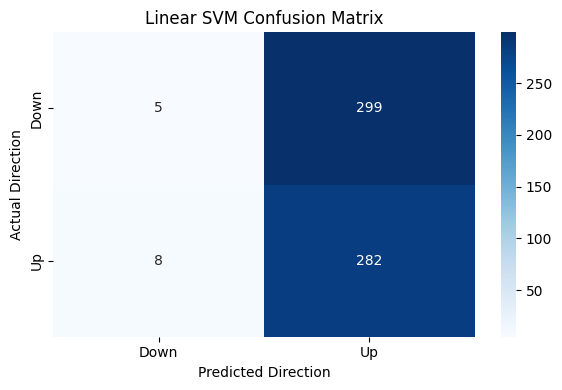

Confusion matrix:
[[  5 299]
 [  8 282]]


In [18]:

from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Down", "Up"],
    yticklabels=["Down", "Up"]
)

plt.xlabel("Predicted Direction")
plt.ylabel("Actual Direction")
plt.title("Linear SVM Confusion Matrix")

plt.tight_layout()
plt.show()

print("Confusion matrix:")
print(cm)


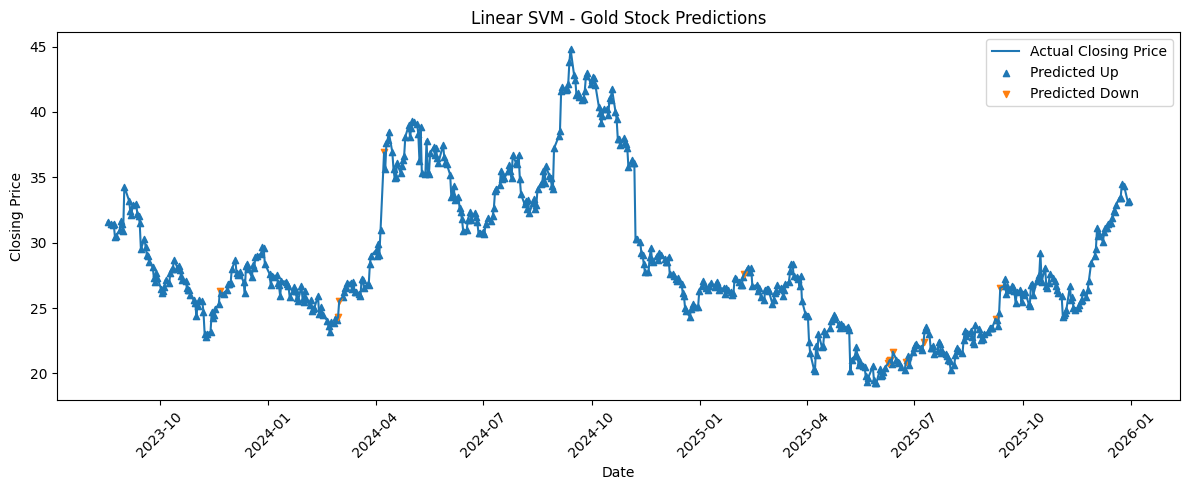

In [19]:

results = df.iloc[split_index:].copy()

results["Predicted"] = y_pred

up = results["Predicted"] == 1
down = results["Predicted"] == 0

plt.figure(figsize=(12, 5))

plt.plot(
    results["Date"],
    results["Close"],
    label="Actual Closing Price"
)

plt.scatter(
    results.loc[up, "Date"],
    results.loc[up, "Close"],
    marker="^",
    s=20,
    label="Predicted Up"
)

plt.scatter(
    results.loc[down, "Date"],
    results.loc[down, "Close"],
    marker="v",
    s=20,
    label="Predicted Down"
)

plt.xlabel("Date")
plt.ylabel("Closing Price")
plt.title("Linear SVM - Gold Stock Predictions")

plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [20]:

from sklearn.svm import SVC

rbf_svm = SVC(
    kernel="rbf",
    C=1.0,
    gamma="scale",
    class_weight="balanced"
)

rbf_svm.fit(X_train_scaled, y_train)

print("RBF SVM model trained successfully!")
print("Kernel:", rbf_svm.kernel)
print("Support vectors:", rbf_svm.n_support_)


RBF SVM model trained successfully!
Kernel: rbf
Support vectors: [1137 1074]


In [21]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Predict test data
y_pred_rbf = rbf_svm.predict(X_test_scaled)

# Calculate performance metrics
print("NON-LINEAR SVM (RBF) PERFORMANCE")

print("Accuracy:",
      round(accuracy_score(y_test, y_pred_rbf), 4))

print("Precision:",
      round(precision_score(y_test, y_pred_rbf, zero_division=0), 4))

print("Recall:",
      round(recall_score(y_test, y_pred_rbf, zero_division=0), 4))

print("F1-score:",
      round(f1_score(y_test, y_pred_rbf, zero_division=0), 4))

print("\nClassification Report:")

print(classification_report(
    y_test,
    y_pred_rbf,
    labels=[0, 1],
    target_names=["Down", "Up"],
    zero_division=0
))


NON-LINEAR SVM (RBF) PERFORMANCE
Accuracy: 0.4815
Precision: 0.4802
Recall: 0.7517
F1-score: 0.586

Classification Report:
              precision    recall  f1-score   support

        Down       0.49      0.22      0.31       304
          Up       0.48      0.75      0.59       290

    accuracy                           0.48       594
   macro avg       0.48      0.49      0.45       594
weighted avg       0.48      0.48      0.44       594



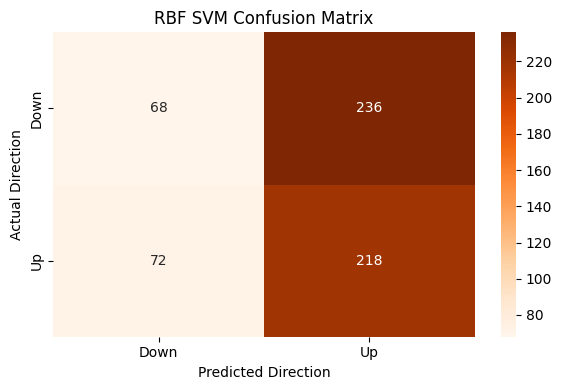

RBF confusion matrix:
[[ 68 236]
 [ 72 218]]


In [22]:

cm_rbf = confusion_matrix(y_test, y_pred_rbf, labels=[0, 1])

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_rbf,
    annot=True,
    fmt="d",
    cmap="Oranges",
    xticklabels=["Down", "Up"],
    yticklabels=["Down", "Up"]
)

plt.xlabel("Predicted Direction")
plt.ylabel("Actual Direction")
plt.title("RBF SVM Confusion Matrix")

plt.tight_layout()
plt.show()

print("RBF confusion matrix:")
print(cm_rbf)


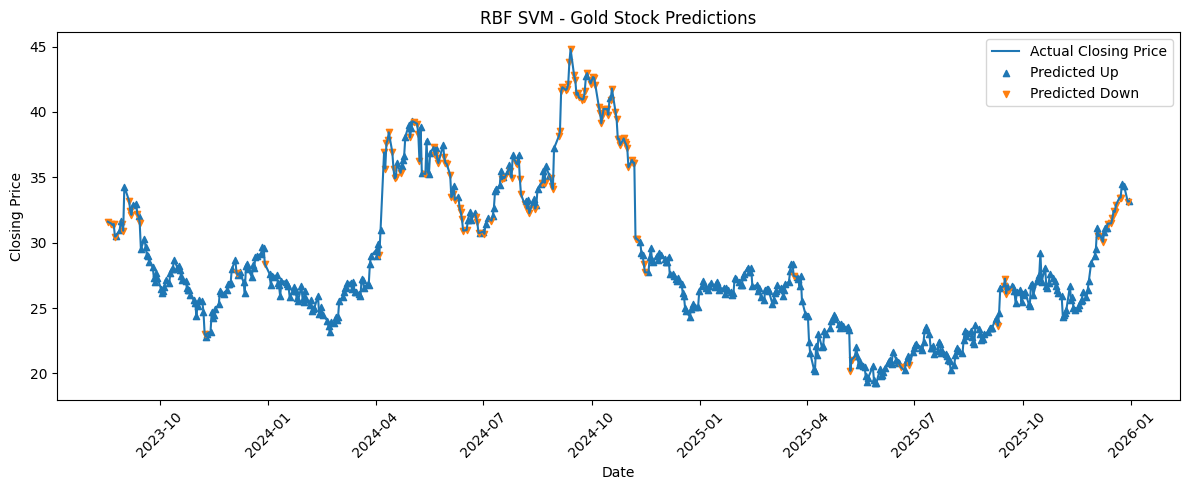

In [23]:

results_rbf = df.iloc[split_index:].copy()
results_rbf["Predicted"] = y_pred_rbf

up = results_rbf["Predicted"] == 1
down = results_rbf["Predicted"] == 0

plt.figure(figsize=(12, 5))

plt.plot(
    results_rbf["Date"],
    results_rbf["Close"],
    label="Actual Closing Price"
)

plt.scatter(
    results_rbf.loc[up, "Date"],
    results_rbf.loc[up, "Close"],
    marker="^",
    s=20,
    label="Predicted Up"
)

plt.scatter(
    results_rbf.loc[down, "Date"],
    results_rbf.loc[down, "Close"],
    marker="v",
    s=20,
    label="Predicted Down"
)

plt.xlabel("Date")
plt.ylabel("Closing Price")
plt.title("RBF SVM - Gold Stock Predictions")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [24]:

from sklearn.svm import SVC

poly_svm = SVC(
    kernel="poly",
    C=1.0,
    degree=3,
    gamma="scale",
    coef0=1.0,
    class_weight="balanced"
)

poly_svm.fit(X_train_scaled, y_train)

print("Polynomial SVM trained successfully!")
print("Kernel:", poly_svm.kernel)
print("Degree:", poly_svm.degree)
print("Support vectors:", poly_svm.n_support_)


Polynomial SVM trained successfully!
Kernel: poly
Degree: 3
Support vectors: [1121 1057]


In [25]:

y_pred_poly = poly_svm.predict(X_test_scaled)

print("POLYNOMIAL SVM PERFORMANCE")

print("Accuracy:",
      round(accuracy_score(y_test, y_pred_poly), 4))

print("Precision:",
      round(precision_score(y_test, y_pred_poly, zero_division=0), 4))

print("Recall:",
      round(recall_score(y_test, y_pred_poly, zero_division=0), 4))

print("F1-score:",
      round(f1_score(y_test, y_pred_poly, zero_division=0), 4))

print("\nClassification Report:")

print(classification_report(
    y_test,
    y_pred_poly,
    labels=[0, 1],
    target_names=["Down", "Up"],
    zero_division=0
))


POLYNOMIAL SVM PERFORMANCE
Accuracy: 0.4865
Precision: 0.4838
Recall: 0.7724
F1-score: 0.595

Classification Report:
              precision    recall  f1-score   support

        Down       0.50      0.21      0.30       304
          Up       0.48      0.77      0.59       290

    accuracy                           0.49       594
   macro avg       0.49      0.49      0.45       594
weighted avg       0.49      0.49      0.44       594



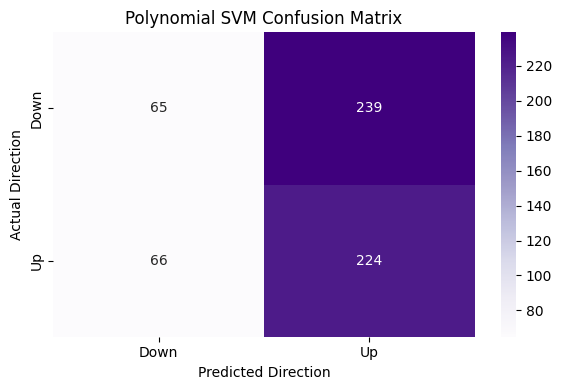

Polynomial confusion matrix:
[[ 65 239]
 [ 66 224]]


In [26]:

cm_poly = confusion_matrix(
    y_test, y_pred_poly, labels=[0, 1]
)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_poly,
    annot=True,
    fmt="d",
    cmap="Purples",
    xticklabels=["Down", "Up"],
    yticklabels=["Down", "Up"]
)

plt.xlabel("Predicted Direction")
plt.ylabel("Actual Direction")
plt.title("Polynomial SVM Confusion Matrix")

plt.tight_layout()
plt.show()

print("Polynomial confusion matrix:")
print(cm_poly)



In [27]:

sigmoid_svm = SVC(
    kernel="sigmoid",
    C=1.0,
    gamma="scale",
    coef0=0.0,
    class_weight="balanced"
)

sigmoid_svm.fit(X_train_scaled, y_train)

print("Sigmoid SVM trained successfully!")
print("Kernel:", sigmoid_svm.kernel)
print("Support vectors:", sigmoid_svm.n_support_)


Sigmoid SVM trained successfully!
Kernel: sigmoid
Support vectors: [722 675]


In [28]:

y_pred_sigmoid = sigmoid_svm.predict(X_test_scaled)

print("SIGMOID SVM PERFORMANCE")

print("Accuracy:",
      round(accuracy_score(y_test, y_pred_sigmoid), 4))

print("Precision:",
      round(precision_score(y_test, y_pred_sigmoid, zero_division=0), 4))

print("Recall:",
      round(recall_score(y_test, y_pred_sigmoid, zero_division=0), 4))

print("F1-score:",
      round(f1_score(y_test, y_pred_sigmoid, zero_division=0), 4))

print("\nClassification Report:")

print(classification_report(
    y_test,
    y_pred_sigmoid,
    labels=[0, 1],
    target_names=["Down", "Up"],
    zero_division=0
))


SIGMOID SVM PERFORMANCE
Accuracy: 0.4798
Precision: 0.4768
Recall: 0.6724
F1-score: 0.5579

Classification Report:
              precision    recall  f1-score   support

        Down       0.49      0.30      0.37       304
          Up       0.48      0.67      0.56       290

    accuracy                           0.48       594
   macro avg       0.48      0.48      0.46       594
weighted avg       0.48      0.48      0.46       594



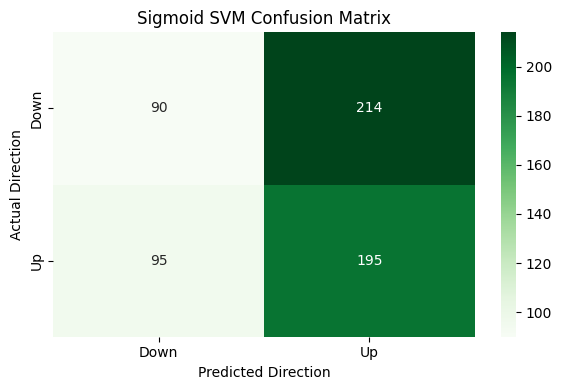

Sigmoid confusion matrix:
[[ 90 214]
 [ 95 195]]


In [29]:

cm_sigmoid = confusion_matrix(
    y_test, y_pred_sigmoid, labels=[0, 1]
)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_sigmoid,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["Down", "Up"],
    yticklabels=["Down", "Up"]
)

plt.xlabel("Predicted Direction")
plt.ylabel("Actual Direction")
plt.title("Sigmoid SVM Confusion Matrix")

plt.tight_layout()
plt.show()

print("Sigmoid confusion matrix:")
print(cm_sigmoid)


In [30]:

results = {
    "Model": [
        "Linear SVM",
        "RBF SVM",
        "Polynomial SVM",
        "Sigmoid SVM"
    ],
    "Accuracy": [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, y_pred_rbf),
        accuracy_score(y_test, y_pred_poly),
        accuracy_score(y_test, y_pred_sigmoid)
    ],
    "Precision": [
        precision_score(y_test, y_pred, zero_division=0),
        precision_score(y_test, y_pred_rbf, zero_division=0),
        precision_score(y_test, y_pred_poly, zero_division=0),
        precision_score(y_test, y_pred_sigmoid, zero_division=0)
    ],
    "Recall": [
        recall_score(y_test, y_pred, zero_division=0),
        recall_score(y_test, y_pred_rbf, zero_division=0),
        recall_score(y_test, y_pred_poly, zero_division=0),
        recall_score(y_test, y_pred_sigmoid, zero_division=0)
    ],
    "F1-score": [
        f1_score(y_test, y_pred, zero_division=0),
        f1_score(y_test, y_pred_rbf, zero_division=0),
        f1_score(y_test, y_pred_poly, zero_division=0),
        f1_score(y_test, y_pred_sigmoid, zero_division=0)
    ]
}

comparison = pd.DataFrame(results)

print(comparison.round(4).to_string(index=False))


         Model  Accuracy  Precision  Recall  F1-score
    Linear SVM    0.4832     0.4854  0.9724    0.6475
       RBF SVM    0.4815     0.4802  0.7517    0.5860
Polynomial SVM    0.4865     0.4838  0.7724    0.5950
   Sigmoid SVM    0.4798     0.4768  0.6724    0.5579


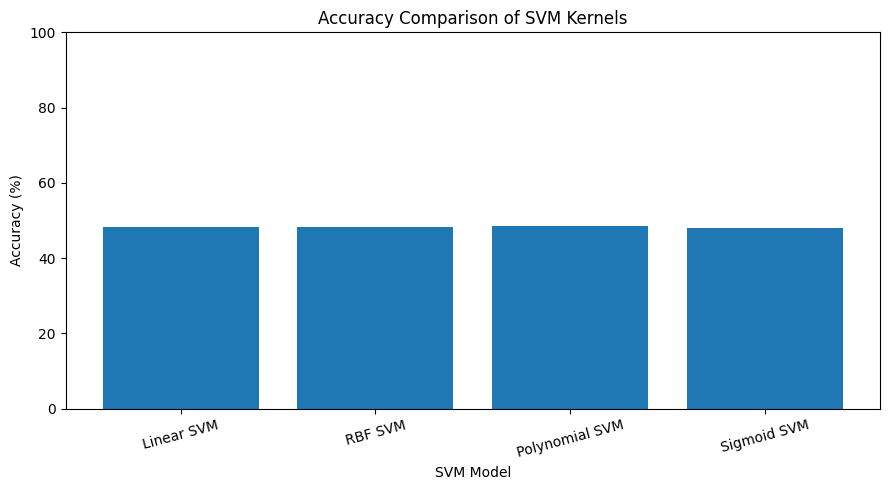

In [31]:

plt.figure(figsize=(9, 5))

plt.bar(
    comparison["Model"],
    comparison["Accuracy"] * 100
)

plt.xlabel("SVM Model")
plt.ylabel("Accuracy (%)")
plt.title("Accuracy Comparison of SVM Kernels")
plt.ylim(0, 100)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()
